#Семинар 7: Распознавание изображений, работа с GigaChat Vision

Работа мультимодальной модели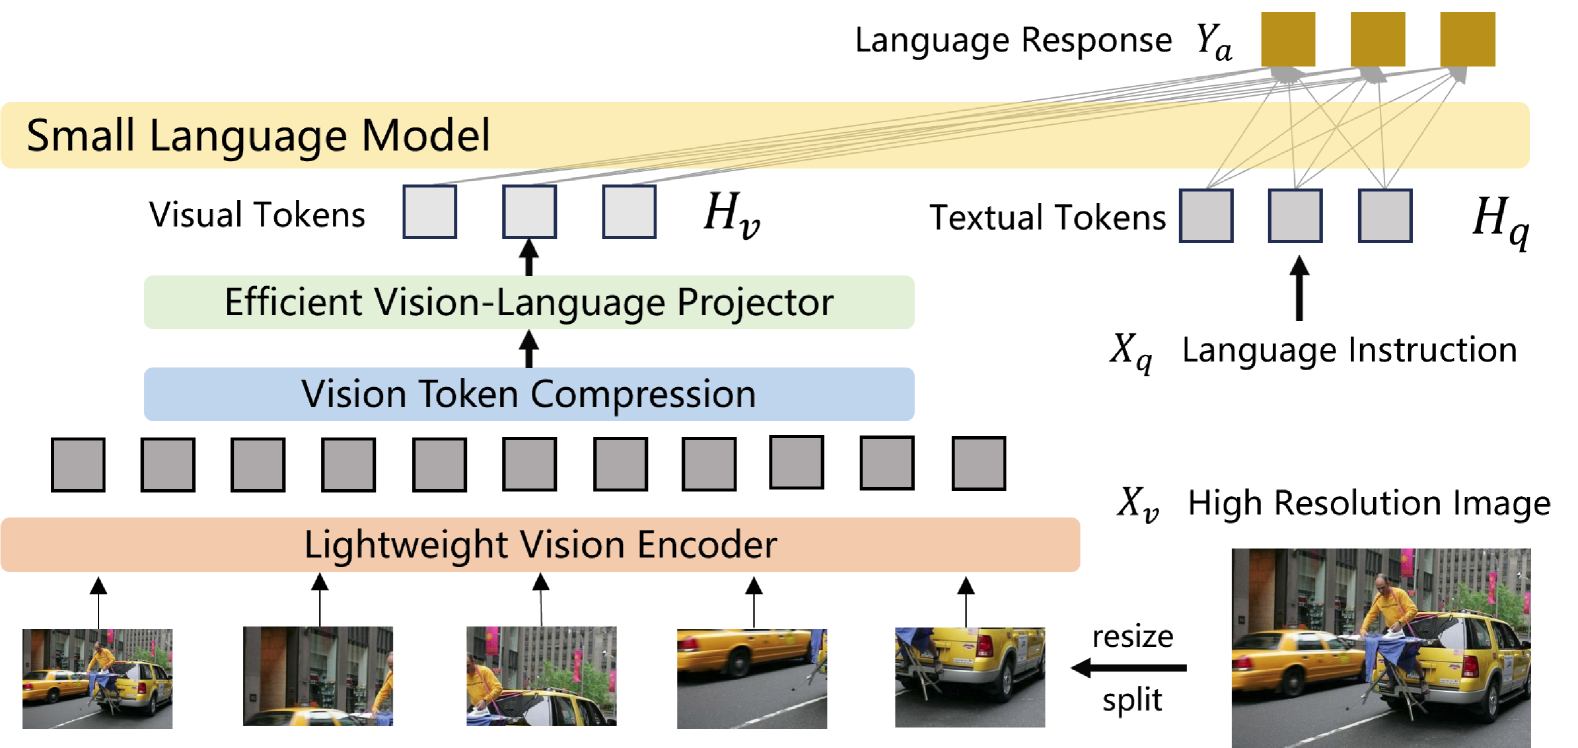

Работа GigaChat Vision с изображениями реализуется следующим образом.
1. Изображение загружается в хранилище и получает свой индивидуальный идентификатор.
2. В пользовательском сообщении в параметре attachments указывается идентификатор изображения. В параметре content указывается текст запроса, на который модель вернет ответ. Если текст запроса будет пустым, тогда модель вернет описание изображения.
1. Возможно задание дополнительных вопросов и организация диалога с моделью по изображению.

Пример:
https://github.com/ai-forever/gigachain/blob/master/cookbook/gigachat_vision/gigachat_vision_simple.ipynb

In [ ]:
!pip install langchain-gigachat langchain langchain-community langchain-classic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 42.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 3.8 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.33.1 which is incompatible.


In [ ]:
from google.colab import userdata
GigaChatKey = userdata.get('GigaChatKey')

In [ ]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_gigachat.chat_models import GigaChat

In [ ]:
giga = GigaChat(credentials=GigaChatKey,
         model='GigaChat-Max',
         verify_ssl_certs=False
)

In [ ]:
image1 = giga.upload_file(open('pic1.jpg', 'rb'))

In [ ]:
image1

UploadedFile(x_headers={'x-request-id': '44d481e2-0a8b-4471-88ed-b802158019de', 'x-session-id': '99ce292e-fb6d-4bc5-b0f3-8726d2bc488c', 'x-client-id': None}, id_='6e19b692-6e93-4de4-980c-502709ae72a7', object_='file', bytes_=112263, created_at=1775321164, filename='pic1.jpg', purpose='general', access_policy='private')

In [ ]:
mes1 = [HumanMessage(content="Что изображено на картинке?", additional_kwargs={"attachments": [image1.id_]})]
answer1 = giga.invoke(mes1)
answer1

AIMessage(content='На фотографии изображен деревянный дом, расположенный в лесной местности. Дом окружен зеленью: деревьями и кустарниками. Видно, что дом имеет крыльцо и несколько окон.', additional_kwargs={}, response_metadata={'token_usage': {'prompt_tokens': 1936, 'completion_tokens': 37, 'total_tokens': 1973, 'precached_prompt_tokens': 11}, 'model_name': 'GigaChat-Max:2.0.28.2', 'x_headers': {'x-request-id': '49e60490-e2e2-4fbc-8a7a-d94f4f26b3b9', 'x-session-id': '1c640a59-5aaf-4a15-94f4-292962bcfffe', 'x-client-id': None}, 'finish_reason': 'stop'}, id='49e60490-e2e2-4fbc-8a7a-d94f4f26b3b9', tool_calls=[], invalid_tool_calls=[], usage_metadata={'output_tokens': 37, 'input_tokens': 1936, 'total_tokens': 1973, 'input_token_details': {'cache_read': 11}})

In [ ]:
dialog = [*mes1, answer1, HumanMessage(content="Предположи, в какой стране сделано фото?")]

giga.invoke(dialog)

AIMessage(content='Судя по архитектуре дома и окружающей природе, фото может быть сделано в России, в одной из лесных зон.', additional_kwargs={}, response_metadata={'token_usage': {'prompt_tokens': 45, 'completion_tokens': 24, 'total_tokens': 69, 'precached_prompt_tokens': 1961}, 'model_name': 'GigaChat-Max:2.0.28.2', 'x_headers': {'x-request-id': '8a2ade39-2a29-4d0e-a396-7ba7fe80f722', 'x-session-id': 'c25fb6a4-2a66-4053-b61f-d699b8b6d337', 'x-client-id': None}, 'finish_reason': 'stop'}, id='8a2ade39-2a29-4d0e-a396-7ba7fe80f722', tool_calls=[], invalid_tool_calls=[], usage_metadata={'output_tokens': 24, 'input_tokens': 45, 'total_tokens': 69, 'input_token_details': {'cache_read': 1961}})

In [ ]:
dialog = [HumanMessage(content="Предположи на какой фотоаппарат сделано фото?", additional_kwargs={"attachments": [image1.id_]})]

giga.invoke(dialog).content

'Судя по качеству изображения, оно сделано на фотоаппарат среднего или высокого класса.  Можно предположить, что это зеркальная или беззеркальная камера с хорошим объективом.  Однако, без дополнительной информации сложно точно определить модель фотоаппарата.'

##Задания на семинар
1. Есть названия 3-х объектов/предметов. Модель принимает изображение и формирует описание этого изображения. Далее LLM определяется присутствие всех 3-х объектов в описании (данный шаг реализовать с помощью цепочки chain). Если все объекты присутствуют, то генерируем изображение по полученному от LLM описанию. Если какие-то объекты отсутствуют, то генерируется изображение, содержащее только отсутствующие объекты.
4. Первая цепочка создает детальное текстовое описание сцены на изображении. Вторая ищет в описании указания на три стилевых признака (например, "готический", "футуристический", "ретро"). Если все три найдены, генерируется изображение по описанию в одном из этих стилей (случайно выбранном). Если нет, генерируется изображение в нейтральном стиле, но содержащее только те объекты, которые НЕ были связаны с искомыми стилями.

In [ ]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_gigachat.chat_models import GigaChat

from langchain_core.prompts import PromptTemplate

from IPython.display import display, Markdown, Image

import requests
import json
from bs4 import BeautifulSoup
import random

In [ ]:
#Получение токена. Токен будет действовать 30 минут. После этого запустите ячейку заново.
import requests
import uuid

rq_uid = str(uuid.uuid4())
#URL API, к которому мы обращаемся
url = "https://ngw.devices.sberbank.ru:9443/api/v2/oauth"

#Данные для запроса
payload={
    'scope': 'GIGACHAT_API_PERS'
}
#Заголовки запроса
headers = {
    'Content-Type': 'application/x-www-form-urlencoded',
    'Accept': 'application/json',
    'RqUID': rq_uid,
    'Authorization': f'Basic {GigaChatKey}'
}

response = requests.request("POST", url, headers=headers, data=payload, verify=False) # verify=False Отключает проверку наличия сертификатов НУЦ Минцифры
giga_token = response.json()['access_token']

/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'ngw.devices.sberbank.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


In [ ]:
giga = GigaChat(credentials=GigaChatKey,
         model='GigaChat-Max',
         verify_ssl_certs=False
)
giga_url = "https://gigachat.devices.sberbank.ru/api/v1/chat/completions"
llm = GigaChat(
    credentials=GigaChatKey,
    scope="GIGACHAT_API_PERS",
    model="GigaChat",
    verify_ssl_certs=False, # Отключает проверку наличия сертификатов НУЦ Минцифры
    streaming=False,
)

In [ ]:
image1 = giga.upload_file(open('pic2.jpg', 'rb'))

mes1 = [HumanMessage(content="Что изображено не картинке?", additional_kwargs={"attachments": [image1.id_]})]
descr = giga.invoke(mes1)
descr.content

'На картинке изображена сельская местность в дождливую погоду. Видны деревянные дома с крышами из шифера, лужи на дороге, деревья и пасмурное небо.'

In [ ]:
image1

UploadedFile(x_headers={'x-request-id': '2524592c-b3c6-4fdf-a3d6-6cae45114049', 'x-session-id': 'b0ef83c9-7537-4702-abe2-99641fc8ed9d', 'x-client-id': None}, id_='d29ccaf9-d292-4caa-b7d5-f341e0e09be4', object_='file', bytes_=177921, created_at=1776252115, filename='pic4.jpg', purpose='general', access_policy='private')

In [ ]:
key_words = ['деревья', 'цветы', 'радуга']

prompt = PromptTemplate.from_template("""Проверь наличие в тексте слов в любой грамматической форме: {key_words}. Текст: {descr}.
                                      Просто выведи слово, если оно есть в тексте. Не пиши какие слова отсутствуют!""")

chain = (lambda x: {"key_words": key_words, "descr": x}) | prompt | llm

llm_chain_answ = chain.invoke(descr.content)
print("Присутствуют слова:", llm_chain_answ.content)

missing_words = [w for w in key_words if w not in llm_chain_answ.content]
print("Отсутствуют слова:", missing_words)

img_prompt = ''
if (len(missing_words) == 0):
  img_prompt = descr.content
else:
  img_prompt = ' '.join(missing_words)

print("Итоговый промт для создания картинки:", img_prompt)

Присутствуют слова: деревья
Отсутствуют слова: ['цветы', 'радуга']
Итоговый промт для создания картинки: цветы радуга


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'gigachat.devices.sberbank.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'gigachat.devices.sberbank.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


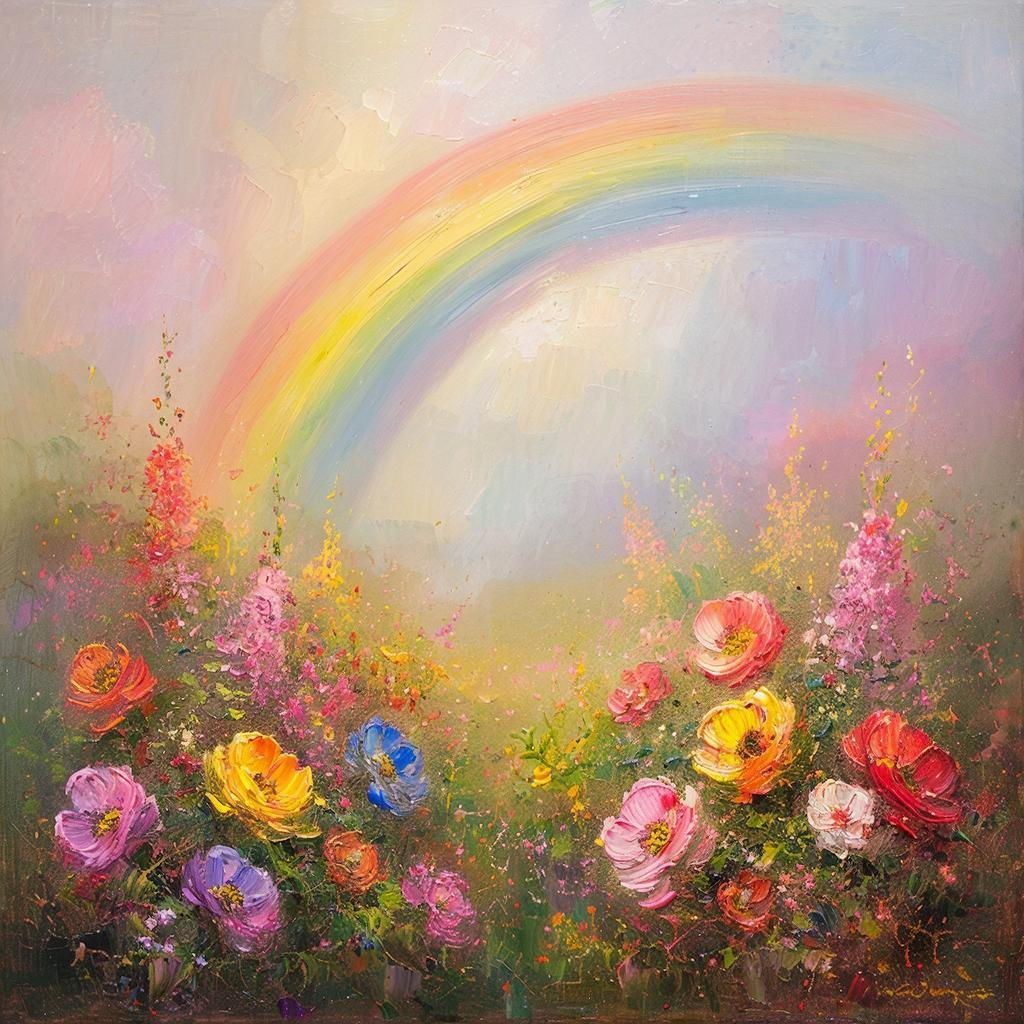

In [ ]:
payload = json.dumps({
    "model": "GigaChat",
    "messages": [
      { "role": "system", "content": "Ты - художник реалист" },
      { "role": "user", "content": f"Создай картину на которой изображена {img_prompt}. Стиль - маслянная живопись."}
    ],
    "function_call": "auto"
  })

headers = {
    'Accept': 'application/json',
    'Authorization': f'Bearer {giga_token}'
  }

answer = requests.request("POST", giga_url, headers=headers, data=payload, verify=False).json()
answ = answer['choices'][0]['message']['content']

src = BeautifulSoup(answ, 'html.parser').find('img').get('src')
url = f"https://gigachat.devices.sberbank.ru/api/v1/files/{src}/content"
response = requests.request("GET", url, headers=headers, data=payload, verify=False)

with open(f"image2.png", "wb") as img_file:
  img_file.write(response.content)
display(Image("image2.png"))

### ..................................................................................................

In [ ]:
image1 = giga.upload_file(open('pic4.jpg', 'rb')) # pic4 - в, pic5 - гp

mes1 = [HumanMessage(content="Что изображено на картинке?", additional_kwargs={"attachments": [image1.id_]})]
descr = giga.invoke(mes1)
descr.content

'На картинке изображен замок в стиле стимпанк. Он выполнен в темных тонах с преобладанием черного и коричневого цветов. Архитектура замка сочетает в себе элементы готики и индустриального дизайна. Видны высокие башни с острыми шпилями, украшенные витиеватыми узорами. Стены замка украшены различными механическими деталями, такими как шестеренки, трубы и рычаги. В некоторых местах видны элементы, напоминающие старинные радиоприемники и другие устройства. Общая атмосфера изображения мрачная и загадочная, что характерно для стимпанк-эстетики.'

In [ ]:
llm = GigaChat(
    credentials=GigaChatKey,
    scope="GIGACHAT_API_PERS",
    model="GigaChat",
    verify_ssl_certs=False, # Отключает проверку наличия сертификатов НУЦ Минцифры
    streaming=False,
)

prompt = PromptTemplate.from_template("""Проверь описание картинки {descr} на наличие трёх стилей: готического, футуристического и ретро.
                                      Либо напиши только те стили, которые НЕ были связаны с перечисленными стилями. Без объяснений.
                                      Либо если СТРОГО ВСЕ три стиля присутствуют в описании, выведи простой ответ 'все'.""")

chain = prompt | llm

llm_chain_answ = chain.invoke(descr.content)
print(llm_chain_answ.content)

готический  
индустриальный (стимпанк)  
нет футуристического  
нет ретро

**Все:** Готика + стимпанк → **все**


Случайный выбранный стиль: футуристический


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'gigachat.devices.sberbank.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'gigachat.devices.sberbank.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


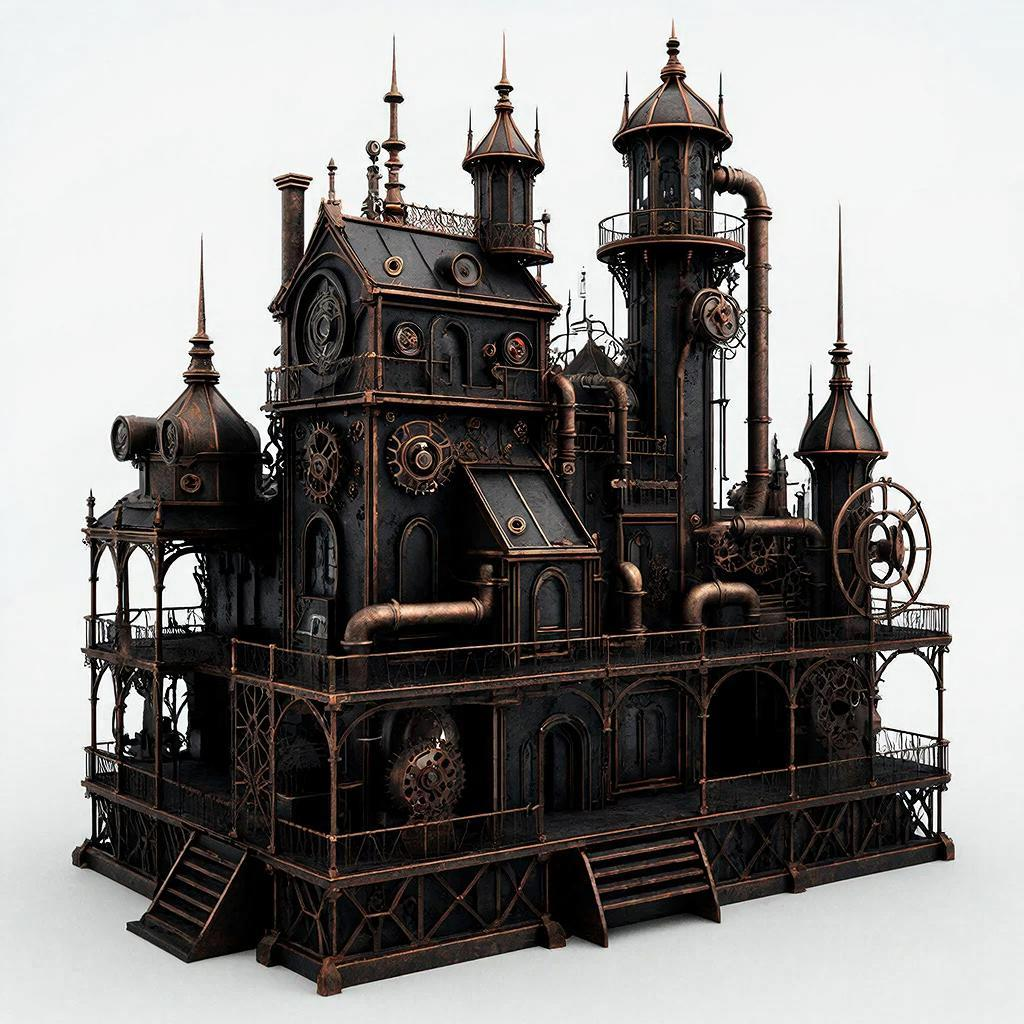

In [ ]:
missing_elements = ""

if 'все' in llm_chain_answ.content.lower():
  style = random.choice(['готический', 'футуристический', 'ретро'])
  print("Случайный выбранный стиль:", style)
  payload = json.dumps({
    "model": "GigaChat",
    "messages": [
      { "role": "system", "content": "Ты - художник реалист" },
      { "role": "user", "content": f"Создай картину по описанию {descr.content}. Стиль - {style}"}
    ],
    "function_call": "auto"
  })

else:
  payload = json.dumps({
    "model": "GigaChat",
    "messages": [
      { "role": "system", "content": "Ты - художник реалист" },
      { "role": "user", "content": f"Создай картинку, изобрази то, что не относится к готике, ретро или футуризму в данном описании: {llm_chain_answ.content}. Стиль - нейтральный."}
    ],
    "function_call": "auto"
  })

headers = {
    'Accept': 'application/json',
    'Authorization': f'Bearer {giga_token}'
  }

answer = requests.request("POST", giga_url, headers=headers, data=payload, verify=False).json()
answ = answer['choices'][0]['message']['content']

src = BeautifulSoup(answ, 'html.parser').find('img').get('src')
url = f"https://gigachat.devices.sberbank.ru/api/v1/files/{src}/content"
response = requests.request("GET", url, headers=headers, data=payload, verify=False)

with open(f"image3.png", "wb") as img_file:
  img_file.write(response.content)
display(Image("image3.png"))

/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'gigachat.devices.sberbank.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'gigachat.devices.sberbank.ru'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


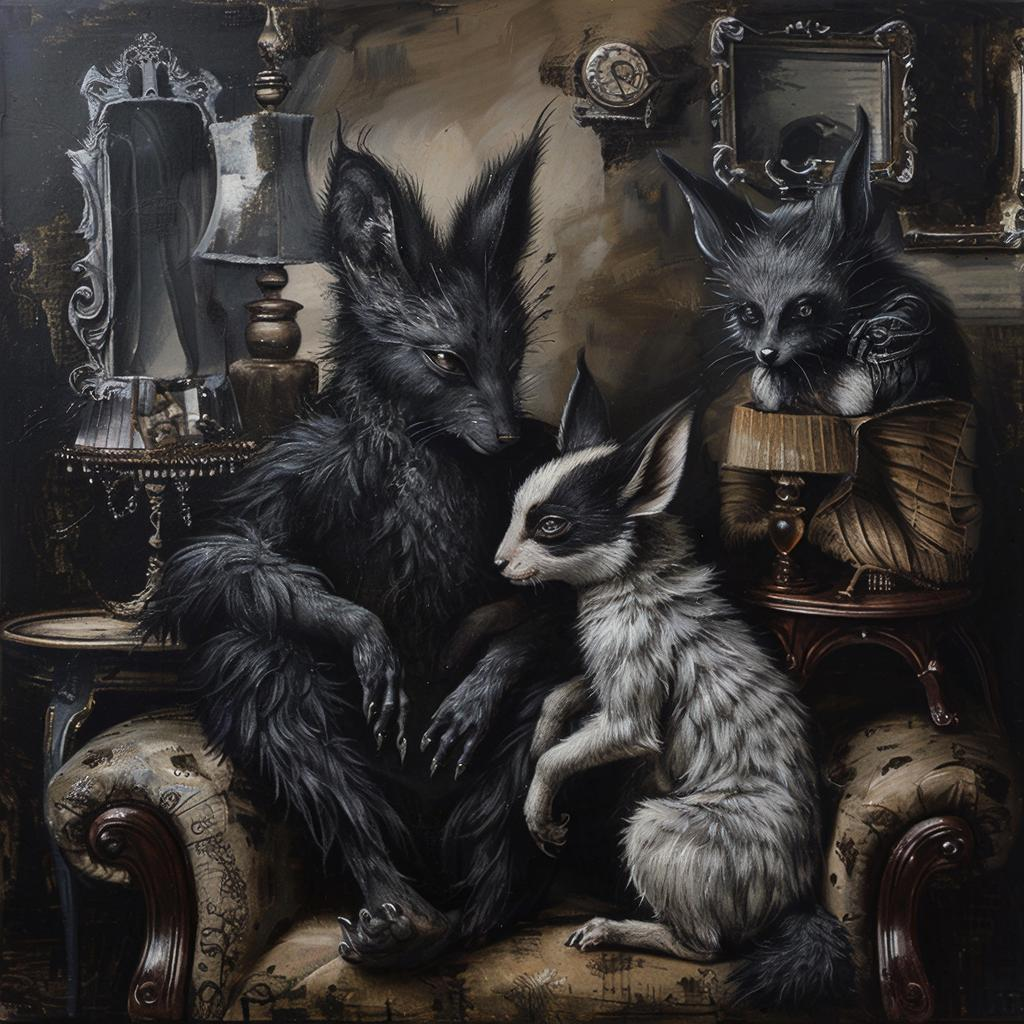

In [ ]:
# ДЛЯ СОЗДАНИЯ КАРТИНКИ ДЛЯ ВТОРОГО ЗАДАНИЯ

payload = json.dumps({
    "model": "GigaChat",
    "messages": [
      { "role": "system", "content": "Ты - художник" },
      { "role": "user", "content": f"Создай картину, в которой будут три стиля. Стили: ФУИУРИЗМ, ГОТИКА и РЕТРО."}
    ],
    "function_call": "auto"
  })

headers = {
    'Accept': 'application/json',
    'Authorization': f'Bearer {giga_token}'
  }

answer = requests.request("POST", giga_url, headers=headers, data=payload, verify=False).json()
answ = answer['choices'][0]['message']['content']

src = BeautifulSoup(answ, 'html.parser').find('img').get('src')
url = f"https://gigachat.devices.sberbank.ru/api/v1/files/{src}/content"
response = requests.request("GET", url, headers=headers, data=payload, verify=False)

with open(f"pic4.png", "wb") as img_file:
  img_file.write(response.content)
display(Image("pic4.png"))